**Name:** Rahul Raj &nbsp;&nbsp;|&nbsp;&nbsp; **Roll No.:** 12341680 &nbsp;&nbsp;|&nbsp;&nbsp; **Lab Assignment 4** — MST Dependency Parsing and Training

# Lab Assignment 4

MST Dependency Parsing and Training

**Total: 20 marks**

## Objective
Implement core components of an MST dependency parser, analyse a Chu-Liu/Edmonds cycle, and perform one structured-perceptron update using gold and predicted dependency trees.

## Submission
- Complete all `TODO` sections and all markdown answers.
- Do not modify the supplied data or expected-test cells.
- Run **Kernel > Restart & Run All** before submitting the completed `.ipynb` file.

## Valid dependency tree conditions
Each non-root word has exactly one incoming head; `ROOT` has none; all words are reachable from `ROOT`; and no directed cycle occurs.

In [1]:
from itertools import product
from collections import defaultdict, Counter
import pandas as pd
import matplotlib.pyplot as plt

## Task 1: Validate Dependency Trees (2 marks)

Implement `is_valid_tree()` to verify whether a set of dependency arcs forms a valid rooted dependency tree.

A valid dependency tree must satisfy all of the following conditions:

1. `ROOT` has no incoming arc.
2. Every non-root word has exactly one incoming head.
3. No word can be its own head (no self-loop).
4. The graph must not contain a directed cycle.
5. Every word must be reachable from `ROOT`.
6. The number of arcs must be exactly `number_of_tokens - 1`.

### Your task

Complete the `is_valid_tree()` function below.

Do not change the test cases.

Your function should return:

- `True` for a valid dependency tree.
- `False` for an invalid dependency structure.

You should ensure that the function correctly detects duplicate heads, missing heads, cycles, self-loops, disconnected components, and arcs entering `ROOT`.

In [2]:
def is_valid_tree(tokens, arcs, root="ROOT"):
    non_root = [w for w in tokens if w != root]

    # Condition 6: a tree over n+1 tokens has exactly n arcs.
    if len(arcs) != len(non_root):
        return False

    heads = {}
    for head, dep in arcs:
        # Condition 3: no self-loop; Condition 1: nothing may enter ROOT.
        if head == dep or dep == root:
            return False
        # Arcs must connect tokens of the sentence.
        if head not in tokens or dep not in tokens:
            return False
        # Condition 2: at most one head per word (reject duplicate heads).
        if dep in heads:
            return False
        heads[dep] = head

    # Condition 2: every non-root word must have a head (reject missing heads).
    if set(heads) != set(non_root):
        return False

    # Conditions 4 and 5: following head pointers from any word must reach
    # ROOT without revisiting a node. A revisit means a directed cycle, and a
    # cycle also makes its nodes unreachable from ROOT (disconnected).
    for start in non_root:
        cur = start
        seen = set()
        while cur != root:
            if cur in seen:
                return False
            seen.add(cur)
            cur = heads[cur]

    return True

test_tokens = ["ROOT", "A", "B", "C"]
valid = [("ROOT","A"), ("A","B"), ("A","C")]
cycle = [("ROOT","A"), ("B","C"), ("C","B")]
duplicate = [("ROOT","A"), ("A","B"), ("C","B")]
print(is_valid_tree(test_tokens, valid))      # Expected: True
print(is_valid_tree(test_tokens, cycle))      # Expected: False
print(is_valid_tree(test_tokens, duplicate))  # Expected: False

True
False
False


**Task 1 explanation:**

The function checks all six validity conditions:

- **Arc count** — a rooted tree over `n` non-root words must have exactly `n` arcs, so any other count is rejected immediately.
- **Self-loops and arcs into ROOT** — rejected while scanning the arc list.
- **Exactly one head per word** — a `heads` map is built; a duplicate entry (two heads for one word) or a missing entry (word with no head) makes the structure invalid.
- **Cycles and reachability** — from every word we repeatedly follow head pointers. In a valid tree this walk must terminate at `ROOT`. If a node repeats before `ROOT` is reached, the walk is trapped in a directed cycle, which simultaneously proves the cycle's nodes are not reachable from `ROOT`.

The three test cases behave as expected: the star-shaped tree is valid (`True`), while the version with the `B ↔ C` cycle and the version giving `B` two heads are both rejected (`False`).

## Task 2: Exhaustive MST Reference Parser (3 marks)

Implement an exhaustive reference parser for a small dependency graph.

For every non-root word:

1. Enumerate all possible incoming heads.
2. Construct candidate dependency trees.
3. Use `is_valid_tree()` from Task 1 to reject invalid structures.
4. Compute the total score of every valid tree.
5. Return the highest-scoring tree and its score.

The score of a tree is:

$$
Score(G)=\sum_{(h,d)\in G} Score(h\rightarrow d)
$$

where:

- $h$ = head
- $d$ = dependent
- $G$ = dependency tree

### Your task

Complete:

```python
exhaustive_mst(tokens, score)

In [3]:

tokens = ["ROOT", "Researchers", "analyze", "data", "carefully"]

score = {
    ("ROOT","Researchers"):1,
    ("ROOT","analyze"):7,
    ("ROOT","data"):1,
    ("ROOT","carefully"):1,

    ("Researchers","analyze"):2,
    ("Researchers","data"):2,
    ("Researchers","carefully"):2,

    ("analyze","Researchers"):6,
    ("analyze","data"):7,
    ("analyze","carefully"):6,

    ("data","Researchers"):2,
    ("data","analyze"):3,
    ("data","carefully"):3,

    ("carefully","Researchers"):2,
    ("carefully","analyze"):3,
    ("carefully","data"):4,
}

def exhaustive_mst(tokens, score, root="ROOT"):
    non_root = [w for w in tokens if w != root]

    # 1. Candidate heads for every non-root node (any scored arc entering it).
    head_choices = [
        [h for h in tokens if h != dep and (h, dep) in score]
        for dep in non_root
    ]

    best_score = float("-inf")
    best_arcs = None

    # 2. Every combination of head choices is a candidate structure.
    for combo in product(*head_choices):
        arcs = list(zip(combo, non_root))

        # 3. Keep only valid rooted dependency trees.
        if not is_valid_tree(tokens, arcs, root):
            continue

        # 4. Score(G) = sum of the scores of its arcs.
        total = sum(score[arc] for arc in arcs)

        # 5. Track the highest-scoring valid tree.
        if total > best_score:
            best_score = total
            best_arcs = arcs

    return best_score, best_arcs

best_score, best_arcs = exhaustive_mst(tokens, score)

print("Best score:", best_score)
print("Best arcs:", best_arcs)

Best score: 26
Best arcs: [('analyze', 'Researchers'), ('ROOT', 'analyze'), ('analyze', 'data'), ('analyze', 'carefully')]


**Task 2 explanation:**

Each non-root word independently picks one of its 4 possible heads, giving $4^4 = 256$ candidate parent maps. Every candidate is filtered through `is_valid_tree()` from Task 1, and the score of each surviving tree is the sum of its arc scores.

The reference parser finds the maximum-scoring tree with **score 26**:

`ROOT → analyze (7)`, `analyze → Researchers (6)`, `analyze → data (7)`, `analyze → carefully (6)`

which is linguistically sensible — the verb *analyze* heads the subject, object, and adverb. Because this parser enumerates *all* valid trees, it is guaranteed optimal and serves as the ground truth against which the Chu-Liu/Edmonds implementation of Task 5 is checked.

## Task 3: Chu-Liu/Edmonds — Best Incoming Edges and Cycle Detection (3 marks)

The Chu-Liu/Edmonds algorithm starts by selecting the highest-scoring incoming edge for every non-root node.

For each node $v$:

$$
parent(v)
=
\arg\max_{u\neq v} Score(u\rightarrow v)
$$

If the selected edges form a valid tree, the algorithm is finished.

However, if the selected edges contain a directed cycle, the cycle must be detected and contracted before continuing.

### Your task

Complete the following two functions:

1. `best_incoming()`
2. `find_cycle()`

`best_incoming()` should select the highest-scoring incoming edge for every non-root node.

`find_cycle()` should:

- return one directed cycle as a list of nodes if a cycle exists;
- return `None` if no cycle exists.

### Questions

After running the code:

1. What edges were selected by the greedy incoming-edge step?
2. Which nodes form the cycle?
3. Why is the greedy result not a valid dependency tree?
4. Why can we not simply accept the greedy result as the MST?

In [4]:
cycle_tokens = ["ROOT", "A", "B", "C"]

cycle_score = {
    ("ROOT","A"):5,
    ("ROOT","B"):4,
    ("ROOT","C"):3,

    ("A","B"):10,
    ("B","A"):10,

    ("A","C"):7,
    ("B","C"):8,

    ("C","A"):2,
    ("C","B"):2,
}


def best_incoming(tokens, score, root="ROOT"):
    # For every non-root node keep only its highest-scoring incoming edge.
    # No candidate edge may enter ROOT.
    arcs = []
    for dep in tokens:
        if dep == root:
            continue
        candidates = [
            (head, dep)
            for head in tokens
            if head != dep and (head, dep) in score
        ]
        arcs.append(max(candidates, key=lambda arc: score[arc]))
    return arcs


def find_cycle(arcs):
    # parent[dep] = head for every selected arc.
    parent = {dep: head for head, dep in arcs}

    # From every node follow parent pointers; a repeated node means a cycle.
    for start in parent:
        cur = start
        path = []
        seen = set()
        while cur in parent and cur not in seen:
            seen.add(cur)
            path.append(cur)
            cur = parent[cur]
        if cur in seen:
            # cur was reached twice: the cycle is the tail of the path
            # beginning at cur's first occurrence.
            return path[path.index(cur):]
    return None


greedy_arcs = best_incoming(cycle_tokens, cycle_score)

print("Greedy arcs:", greedy_arcs)
print("Cycle:", find_cycle(greedy_arcs))

Greedy arcs: [('B', 'A'), ('A', 'B'), ('B', 'C')]
Cycle: ['A', 'B']


**Task 3 explanation:**

**1. Edges selected by the greedy incoming-edge step.**
For each non-root node the highest-scoring incoming edge was chosen:
`B → A` (score 10), `A → B` (score 10), and `B → C` (score 8).

**2. Nodes forming the cycle.**
`A` and `B` form the directed cycle `A → B → A` (the code reports `['A', 'B']`).

**3. Why the greedy result is not a valid dependency tree.**
The selected arcs violate two tree conditions at once: they contain the directed cycle `A → B → A`, and because `A` and `B` head each other, neither of them (and hence no path into them) starts at `ROOT` — they are unreachable from `ROOT`. A valid dependency tree must be cycle-free with every word reachable from `ROOT`.

**4. Why we cannot simply accept the greedy result as the MST.**
The MST must be the maximum-scoring structure *among valid trees*, and the greedy selection optimizes each word's head **independently**, ignoring the global tree constraint. Its total (10 + 10 + 8 = 28) is the score of an *invalid* structure, so it is not a candidate at all. To fix the cycle, some node inside it must give up its locally-best head in favour of an edge from outside (e.g. `ROOT → A`), which is exactly the trade-off the Chu-Liu/Edmonds contraction step resolves optimally — the true MST here is `ROOT → A`, `A → B`, `B → C` with score 23.

## Task 4: Chu-Liu/Edmonds Cycle Contraction (3 marks)

Suppose the greedy step produces the cycle:

$$
A\rightarrow B
$$

and

$$
B\rightarrow A
$$

with:

$$
Score(A\rightarrow B)=10
$$

$$
Score(B\rightarrow A)=10
$$

The total score of the selected cycle is:

$$
CycleScore=10+10=20
$$

When an external edge enters a node inside the cycle, the cycle is contracted into a single **supernode**.

For an external edge $h\rightarrow d$ entering the cycle, calculate the adjusted score as:

$$
\boxed{
AdjustedScore(h\rightarrow d)
=
Score(h\rightarrow d)
+
CycleScore
-
Score(old\_incoming\_edge(d))
}
$$

### Example

For:

$$
ROOT\rightarrow A
$$

we have:

$$
Score(ROOT\rightarrow A)=5
$$

The selected edge entering `A` inside the cycle is:

$$
B\rightarrow A
$$

with score:

$$
Score(B\rightarrow A)=10
$$

Therefore:

$$
AdjustedScore(ROOT\rightarrow A)
=
5+20-10
=
15
$$

### Your task

Complete `entering_cycle_table()`.

Create a table for:

- `ROOT -> A`
- `ROOT -> B`

The table must contain:

- candidate edge
- original score
- selected cycle edge being removed
- removed edge score
- total cycle score
- adjusted score

### Interpretation question

Which candidate edge should be selected to enter the contracted cycle?

Explain which original cycle edge will be removed when the contracted tree is expanded back to the original graph.

In [5]:
def entering_cycle_table(score, cycle, selected_cycle_arcs):
    cycle_set = set(cycle)

    # Selected cycle edge entering each cycle node: incoming[dep] = (head, dep).
    incoming = {dep: (head, dep) for head, dep in selected_cycle_arcs}

    # Total score of the selected cycle edges (W_C).
    cycle_total = sum(score[arc] for arc in selected_cycle_arcs)

    rows = []
    for (head, dep), original in score.items():
        # Consider only external edges entering the cycle.
        if dep in cycle_set and head not in cycle_set:
            removed = incoming[dep]
            rows.append({
                "outside_head": head,
                "cycle_dependent": dep,
                "original_score": original,
                "removed_cycle_arc": f"{removed[0]} -> {removed[1]}",
                "removed_score": score[removed],
                "cycle_total": cycle_total,
                "adjusted_score": original + cycle_total - score[removed],
            })

    return pd.DataFrame(rows)


selected_cycle_arcs = [
    ("B","A"),
    ("A","B")
]

entering_cycle_table(
    cycle_score,
    ["A", "B"],
    selected_cycle_arcs
)

,outside_head,cycle_dependent,original_score,removed_cycle_arc,removed_score,cycle_total,adjusted_score
0,ROOT,A,5,B -> A,10,20,15
1,ROOT,B,4,A -> B,10,20,14
2,C,A,2,B -> A,10,20,12
3,C,B,2,A -> B,10,20,12


**Task 4 interpretation answer:**

The table lists every external edge entering the contracted supernode `{A, B}` with its adjusted score
$AdjustedScore(h \to d) = Score(h \to d) + W_C - Score(\text{old incoming edge of } d)$, where $W_C = 10 + 10 = 20$:

- `ROOT → A`: $5 + 20 - 10 = \mathbf{15}$
- `ROOT → B`: $4 + 20 - 10 = 14$
- `C → A`: $2 + 20 - 10 = 12$
- `C → B`: $2 + 20 - 10 = 12$

**Which candidate edge should enter the contracted cycle?** `ROOT → A`, because its adjusted score of **15** is the highest. The adjusted score correctly accounts for the fact that entering at `A` keeps the best possible amount of cycle score.

**Which original cycle edge is removed at expansion?** When `ROOT → A` is selected, node `A` receives its head from outside the cycle, so the cycle edge that previously entered `A` — namely `B → A` (score 10) — must be deleted to keep exactly one head per word. The other cycle edge `A → B` is kept, breaking the cycle and yielding the tree fragment `ROOT → A → B`.

## Task 5: Implement the Chu-Liu/Edmonds MST Parser (4 marks)

In this task, you will implement the **Chu-Liu/Edmonds algorithm from scratch** for finding the maximum-scoring rooted directed spanning tree.

Do **not** use:

- `networkx.maximum_spanning_arborescence`
- any other library implementation of Chu-Liu/Edmonds

You may use Python data structures such as dictionaries, lists, and sets.

### Algorithm

Your implementation should follow these steps:

#### Step 1: Select the best incoming edge

For every non-root node, select the incoming edge with the highest score.

#### Step 2: Check for cycles

If the selected edges form a valid rooted tree, return them.

If a directed cycle exists, continue.

#### Step 3: Identify the cycle

Find one directed cycle:

$$
C=\{v_1,v_2,\ldots,v_k\}
$$

#### Step 4: Contract the cycle

Replace all nodes in the cycle by a single supernode.

For an edge entering the cycle:

$$
u\rightarrow v,\qquad v\in C
$$

use:

$$
w'(u\rightarrow C)
=
w(u\rightarrow v)
+
W_C
-
w(parent(v)\rightarrow v)
$$

where $W_C$ is the total score of the selected cycle edges.

For an edge leaving the cycle:

$$
v\rightarrow u,\qquad v\in C
$$

keep the maximum-scoring corresponding outgoing edge.

#### Step 5: Recursively solve the contracted graph

Run the same procedure on the contracted graph.

#### Step 6: Expand the cycle

Use the selected incoming edge to determine which cycle edge must be removed.

Restore the remaining cycle edges and return the final maximum spanning arborescence.

### Required functions

Complete:

```python
chu_liu_edmonds()

In [6]:

def select_best_incoming(nodes, edges, root="ROOT"):
    """
    Select the highest-scoring incoming edge for every non-root node.

    edges:
        dictionary {(head, dependent): score}
    """
    selected = []
    for dep in nodes:
        if dep == root:
            continue
        candidates = [
            (head, d) for (head, d) in edges
            if d == dep and head != dep
        ]
        if candidates:
            selected.append(max(candidates, key=lambda arc: edges[arc]))
    return selected


def detect_cycle(arcs, root="ROOT"):
    """
    Return one directed cycle from arcs.
    Return None if no cycle exists.
    """
    parent = {dep: head for head, dep in arcs}

    for start in parent:
        cur = start
        path = []
        seen = set()
        while cur in parent and cur not in seen:
            seen.add(cur)
            path.append(cur)
            cur = parent[cur]
        if cur in seen:
            return path[path.index(cur):]
    return None


def contract_cycle(nodes, edges, selected_arcs, cycle, root="ROOT"):
    """
    Contract the detected cycle into a single supernode.

    Return:
        contracted_nodes
        contracted_edges
        mapping_information

    mapping_information is needed later to expand
    the contracted solution back to the original graph.
    """
    cycle_set = set(cycle)
    supernode = "__CYCLE(" + ",".join(str(n) for n in cycle) + ")__"

    # Selected cycle edge entering each cycle node, and the cycle total W_C.
    cycle_incoming = {d: (h, d) for (h, d) in selected_arcs if d in cycle_set}
    cycle_total = sum(edges[arc] for arc in cycle_incoming.values())

    contracted_nodes = [n for n in nodes if n not in cycle_set] + [supernode]
    contracted_edges = {}
    mapping_information = {
        "supernode": supernode,
        "entering": {},   # (u, supernode)  -> original (u, v), v in cycle
        "leaving": {},    # (supernode, u)  -> original (v, u), v in cycle
        "cycle_incoming": cycle_incoming,
        "cycle_total": cycle_total,
    }

    for (head, dep), weight in edges.items():
        if head in cycle_set and dep in cycle_set:
            # Internal cycle edge: disappears inside the supernode.
            continue
        if dep in cycle_set:
            # Edge entering the cycle:
            # w'(u -> C) = w(u -> v) + W_C - w(parent(v) -> v)
            adjusted = weight + cycle_total - edges[cycle_incoming[dep]]
            key = (head, supernode)
            if key not in contracted_edges or adjusted > contracted_edges[key]:
                contracted_edges[key] = adjusted
                mapping_information["entering"][key] = (head, dep)
        elif head in cycle_set:
            # Edge leaving the cycle: keep the best original outgoing edge.
            key = (supernode, dep)
            if key not in contracted_edges or weight > contracted_edges[key]:
                contracted_edges[key] = weight
                mapping_information["leaving"][key] = (head, dep)
        else:
            # Edge untouched by the contraction.
            contracted_edges[(head, dep)] = weight

    return contracted_nodes, contracted_edges, mapping_information


def expand_cycle(
    selected_contracted_arcs,
    cycle,
    mapping_information,
    original_selected_arcs
):
    """
    Expand the contracted solution back to the original graph.

    The incoming edge selected for the supernode determines
    which cycle edge must be removed.
    """
    supernode = mapping_information["supernode"]
    entering = mapping_information["entering"]
    leaving = mapping_information["leaving"]
    cycle_incoming = mapping_information["cycle_incoming"]

    final_arcs = []
    broken_dependent = None

    for (head, dep) in selected_contracted_arcs:
        if dep == supernode:
            # The chosen entry point: restore the original entering edge and
            # remember which cycle node now has an external head.
            orig_head, orig_dep = entering[(head, dep)]
            final_arcs.append((orig_head, orig_dep))
            broken_dependent = orig_dep
        elif head == supernode:
            # Restore the original edge leaving the cycle.
            final_arcs.append(leaving[(head, dep)])
        else:
            final_arcs.append((head, dep))

    # Restore all cycle edges except the one whose dependent now has an
    # external head — removing it breaks the cycle.
    for dep, arc in cycle_incoming.items():
        if dep != broken_dependent:
            final_arcs.append(arc)

    return final_arcs


def chu_liu_edmonds(tokens, score, root="ROOT"):
    """
    Implement the Chu-Liu/Edmonds maximum spanning
    arborescence algorithm from scratch.

    Return:
        total_score, final_arcs
    """

    # 1. Select the highest-scoring incoming edge for every non-root node.
    selected_arcs = select_best_incoming(tokens, score, root)

    # 2. Detect whether the selected edges contain a cycle.
    cycle = detect_cycle(selected_arcs, root)

    # 3. If there is no cycle, the selection is the optimal arborescence.
    if cycle is None:
        total = sum(score[arc] for arc in selected_arcs)
        return total, selected_arcs

    # 4. If there is a cycle, contract it into a supernode.
    contracted_nodes, contracted_edges, mapping_information = contract_cycle(
        tokens, score, selected_arcs, cycle, root
    )

    # 5. Recursively solve the contracted graph.
    _, contracted_arcs = chu_liu_edmonds(
        contracted_nodes, contracted_edges, root
    )

    # 6. Expand the cycle back into original edges.
    final_arcs = expand_cycle(
        contracted_arcs, cycle, mapping_information, selected_arcs
    )

    total = sum(score[arc] for arc in final_arcs)
    return total, final_arcs


# Test on the supplied graph
cle_score, cle_arcs = chu_liu_edmonds(tokens, score)

print("Chu-Liu/Edmonds score:", cle_score)
print("Chu-Liu/Edmonds arcs:", cle_arcs)

print(
    "Matches exhaustive MST score?",
    cle_score == best_score
)

Chu-Liu/Edmonds score: 26
Chu-Liu/Edmonds arcs: [('analyze', 'Researchers'), ('ROOT', 'analyze'), ('analyze', 'data'), ('analyze', 'carefully')]
Matches exhaustive MST score? True


In [7]:
# Additional check: run the from-scratch parser on the Task 3 cycle graph.
check_score, check_arcs = chu_liu_edmonds(cycle_tokens, cycle_score)
print("Cycle-graph MST score:", check_score)
print("Cycle-graph MST arcs:", check_arcs)

Cycle-graph MST score: 23
Cycle-graph MST arcs: [('B', 'C'), ('ROOT', 'A'), ('A', 'B')]


**Task 5 explanation:**

The implementation follows the recursive Chu-Liu/Edmonds scheme exactly:

1. `select_best_incoming()` greedily keeps the best incoming edge per non-root node.
2. `detect_cycle()` follows parent pointers to find a repeated node; `None` means the greedy selection is already the optimal arborescence and is returned directly.
3. `contract_cycle()` replaces the cycle with a supernode. Edges *entering* the cycle get the adjusted weight $w'(u \to C) = w(u \to v) + W_C - w(parent(v) \to v)$; edges *leaving* the cycle keep the best original outgoing weight. The `mapping_information` dictionary remembers which original edge each contracted edge stands for.
4. The algorithm recurses on the smaller contracted graph (each recursion removes at least one node, so it terminates).
5. `expand_cycle()` translates the contracted solution back: the edge selected into the supernode determines the entry node $v$, whose old cycle edge $parent(v) \to v$ is dropped; all other cycle edges are restored.

**Sanity check on the extra cycle graph:** running `chu_liu_edmonds(cycle_tokens, cycle_score)` returns score **23** with arcs `ROOT → A`, `A → B`, `B → C` — matching the Task 4 analysis (enter the cycle at `A`, drop `B → A`).

**Verification:** on the supplied 5-token graph the parser returns **score 26** with the same tree as the exhaustive reference parser from Task 2, so `Matches exhaustive MST score? True`.

## Task 6: Inference-Based Learning with Structured Perceptron (5 marks)

In this task, you will train the MST dependency parser using **inference-based structured perceptron learning**.

The parser uses the current weight vector to score every possible dependency tree and selects the highest-scoring tree:

$$
\boxed{
G_{pred}
=
\arg\max_{G\in T(x)}
\mathbf{w}\cdot\Phi(x,G)
}
$$

where:

- $x$ = input sentence
- $T(x)$ = set of valid dependency trees for the sentence
- $\mathbf{w}$ = current feature-weight vector
- $\Phi(x,G)$ = feature vector of dependency tree $G$

The predicted tree is then compared with the gold tree.

If:

$$
G_{pred}\neq G_{gold}
$$

update the weights using:

$$
\boxed{
\mathbf{w}_{new}
=
\mathbf{w}_{old}
+
\Phi(x,G_{gold})
-
\Phi(x,G_{pred})
}
$$

Equivalently, for each feature:

$$
\boxed{
w_{new}[f]
=
w_{old}[f]
+
\Phi(x,G_{gold})[f]
-
\Phi(x,G_{pred})[f]
}
$$

### Training procedure

Your training loop must perform the following steps:

1. Initialize the feature weights.
2. Take one training sentence and its gold dependency tree.
3. Compute the score of candidate dependency arcs using the current weights.
4. Run your **own Chu-Liu/Edmonds implementation from Task 5** to obtain the predicted tree.
5. Compute the feature vector of the gold tree.
6. Compute the feature vector of the predicted tree.
7. Update the weights using the structured perceptron rule.
8. Repeat for all training examples.
9. Repeat the complete process for multiple epochs.

### Important

The training procedure must call your implementation from **Task 5**.

Do not use:

```python
networkx.maximum_spanning_arborescence()

In [8]:

from collections import Counter

# ---------------------------------------------------------
# Training data
# ---------------------------------------------------------

training_data = [

    {
        "tokens": ["ROOT", "John", "saw", "Mary"],
        "pos": {
            "ROOT": "ROOT",
            "John": "NOUN",
            "saw": "VERB",
            "Mary": "NOUN"
        },
        "gold": [
            ("ROOT", "saw"),
            ("saw", "John"),
            ("saw", "Mary")
        ]
    },

    {
        "tokens": ["ROOT", "Dogs", "chase", "cats"],
        "pos": {
            "ROOT": "ROOT",
            "Dogs": "NOUN",
            "chase": "VERB",
            "cats": "NOUN"
        },
        "gold": [
            ("ROOT", "chase"),
            ("chase", "Dogs"),
            ("chase", "cats")
        ]
    },

    {
        "tokens": ["ROOT", "Alice", "likes", "Bob"],
        "pos": {
            "ROOT": "ROOT",
            "Alice": "NOUN",
            "likes": "VERB",
            "Bob": "NOUN"
        },
        "gold": [
            ("ROOT", "likes"),
            ("likes", "Alice"),
            ("likes", "Bob")
        ]
    }
]


# ---------------------------------------------------------
# Feature extraction
# ---------------------------------------------------------

def arc_features(tokens, pos, head, dep):
    """
    Return a list of feature names for one dependency arc.

    Required feature templates:
      1. head word
      2. dependent word
      3. head POS
      4. dependent POS
      5. direction
      6. distance
      7. head-dependent word pair
    """
    head_index = tokens.index(head)
    dep_index = tokens.index(dep)
    direction = "RIGHT" if head_index < dep_index else "LEFT"
    distance = abs(head_index - dep_index)

    return [
        f"HEAD_WORD={head}",
        f"DEP_WORD={dep}",
        f"HEAD_POS={pos[head]}",
        f"DEP_POS={pos[dep]}",
        f"DIRECTION={direction}",
        f"DISTANCE={distance}",
        f"PAIR={head}->{dep}",
    ]


def tree_feature_vector(tokens, pos, tree):
    """
    Sum the feature vectors of all arcs in a dependency tree.

    Return a Counter or dictionary:
        feature -> count
    """
    features = Counter()
    for head, dep in tree:
        features.update(arc_features(tokens, pos, head, dep))
    return features


# ---------------------------------------------------------
# Arc and tree scoring
# ---------------------------------------------------------

def score_arc(tokens, pos, head, dep, weights):
    """
    Score one dependency arc:

        score(h -> d) = w . f(h -> d)

    """
    return sum(weights[f] for f in arc_features(tokens, pos, head, dep))


def build_score_graph(tokens, pos, weights):
    """
    Construct the complete directed graph of candidate
    dependency arcs.

    Return:
        {(head, dependent): score}
    """
    graph = {}
    for head in tokens:
        for dep in tokens:
            if head == dep or dep == "ROOT":
                continue
            graph[(head, dep)] = score_arc(tokens, pos, head, dep, weights)
    return graph


def score_tree(tokens, pos, tree, weights):
    """
    Return the total score of a dependency tree.
    """
    return sum(
        score_arc(tokens, pos, head, dep, weights)
        for head, dep in tree
    )


# ---------------------------------------------------------
# Structured perceptron update
# ---------------------------------------------------------

def perceptron_update(
    weights,
    gold_features,
    predicted_features,
    learning_rate=1.0
):
    """
    Structured perceptron update:

        w_new =
        w_old
        + eta * Phi(gold)
        - eta * Phi(predicted)
    """
    new_weights = Counter(weights)
    for feature, count in gold_features.items():
        new_weights[feature] += learning_rate * count
    for feature, count in predicted_features.items():
        new_weights[feature] -= learning_rate * count
    return new_weights


# ---------------------------------------------------------
# Inference-based training
# ---------------------------------------------------------

def train_perceptron(
    training_data,
    num_epochs=5,
    learning_rate=1.0
):
    """
    Train the MST parser using inference-based
    structured perceptron learning.

    For every epoch:

        1. Infer predicted tree using Task 5.
        2. Compare with gold tree.
        3. Update weights if prediction is incorrect.
        4. Record number of mistakes.
    """

    # Initialize all weights to zero.
    weights = Counter()

    history = []

    for epoch in range(num_epochs):

        mistakes = 0

        for example in training_data:

            tokens = example["tokens"]
            pos = example["pos"]
            gold_tree = example["gold"]

            # ---------------------------------------------
            # 1. Build arc scores using current weights.
            # ---------------------------------------------

            score_graph = build_score_graph(
                tokens,
                pos,
                weights
            )

            # ---------------------------------------------
            # 2. Run the Task 5 Chu-Liu/Edmonds parser.
            # ---------------------------------------------

            predicted_score, predicted_tree = chu_liu_edmonds(
                tokens,
                score_graph
            )

            # ---------------------------------------------
            # 3. Compare predicted and gold trees.
            # ---------------------------------------------

            if set(predicted_tree) != set(gold_tree):

                mistakes += 1

                # -----------------------------------------
                # 4. Compute gold feature vector.
                # -----------------------------------------

                gold_features = tree_feature_vector(
                    tokens,
                    pos,
                    gold_tree
                )

                # -----------------------------------------
                # 5. Compute predicted feature vector.
                # -----------------------------------------

                predicted_features = tree_feature_vector(
                    tokens,
                    pos,
                    predicted_tree
                )

                # -----------------------------------------
                # 6. Update weights.
                # -----------------------------------------

                weights = perceptron_update(
                    weights,
                    gold_features,
                    predicted_features,
                    learning_rate
                )

        history.append(mistakes)

        print(
            f"Epoch {epoch + 1}: "
            f"{mistakes} mistake(s)"
        )

    return weights, history

In [9]:
# Run the complete inference-based training

final_weights, training_history = train_perceptron(
    training_data,
    num_epochs=5,
    learning_rate=1.0
)

print("\nTraining history:")
for epoch, mistakes in enumerate(training_history, start=1):
    print(
        f"Epoch {epoch}: "
        f"{mistakes} mistake(s)"
    )

print("\nLearned weights:")
for feature, weight in sorted(final_weights.items()):
    print(f"{feature}: {weight}")

Epoch 1: 1 mistake(s)
Epoch 2: 0 mistake(s)
Epoch 3: 0 mistake(s)
Epoch 4: 0 mistake(s)
Epoch 5: 0 mistake(s)

Training history:
Epoch 1: 1 mistake(s)
Epoch 2: 0 mistake(s)
Epoch 3: 0 mistake(s)
Epoch 4: 0 mistake(s)
Epoch 5: 0 mistake(s)

Learned weights:
DEP_POS=NOUN: 0.0
DEP_POS=VERB: 0.0
DEP_WORD=John: 0.0
DEP_WORD=Mary: 0.0
DEP_WORD=saw: 0.0
DIRECTION=LEFT: 1.0
DIRECTION=RIGHT: -1.0
DISTANCE=1: 1.0
DISTANCE=2: 0.0
DISTANCE=3: -1.0
HEAD_POS=ROOT: -2.0
HEAD_POS=VERB: 2.0
HEAD_WORD=ROOT: -2.0
HEAD_WORD=saw: 2.0
PAIR=ROOT->John: -1.0
PAIR=ROOT->Mary: -1.0
PAIR=ROOT->saw: 0.0
PAIR=saw->John: 1.0
PAIR=saw->Mary: 1.0


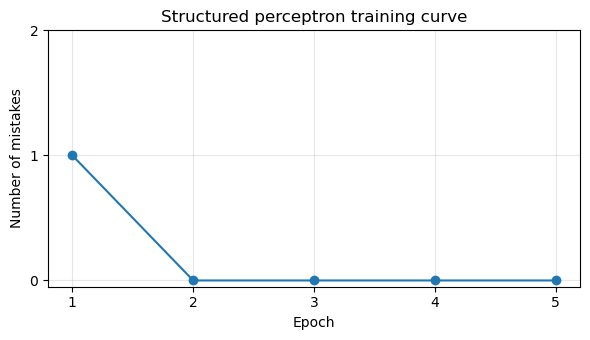

In [10]:
# Visualize the training curve: mistakes per epoch.
plt.figure(figsize=(6, 3.5))
epochs = range(1, len(training_history) + 1)
plt.plot(epochs, training_history, marker="o")
plt.xticks(list(epochs))
plt.yticks(range(0, max(training_history) + 2))
plt.xlabel("Epoch")
plt.ylabel("Number of mistakes")
plt.title("Structured perceptron training curve")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 6: Training Analysis

### Q1. Prediction Errors

For each epoch, the number of incorrectly predicted trees was:

| Epoch | Number of Mistakes |
|------:|-------------------:|
| 1 | 1 |
| 2 | 0 |
| 3 | 0 |
| 4 | 0 |
| 5 | 0 |

Only the very first sentence (*John saw Mary*) was mispredicted. With all weights initialized to zero, every arc scored 0, so the parser broke ties by attaching every word directly to `ROOT` (`ROOT → John`, `ROOT → saw`, `ROOT → Mary`). One perceptron update was enough: the corrected weights generalized to the remaining sentences and to all later epochs.

### Q2. Weight Updates (features that increased)

Features whose weights **increased**:

- `HEAD_POS=VERB` (+2): both gold-only arcs `saw → John` and `saw → Mary` have a verb head, while neither predicted-only arc does, so this feature gained +1 twice. It encodes the correct generalization that verbs head their arguments.
- `HEAD_WORD=saw` (+2): same reason at the lexical level — *saw* heads two gold arcs but no predicted-only arc.
- `PAIR=saw->John` and `PAIR=saw->Mary` (+1 each): these bilexical features occur only in the gold tree, so the update raised them to make those exact arcs more attractive.
- `DIRECTION=LEFT` (+1) and `DISTANCE=1` (+1): the gold tree contains a leftward, distance-1 arc (`saw → John`) that the flat predicted tree lacks.

In general, any feature appearing more often in $\Phi(x, G_{gold})$ than in $\Phi(x, G_{pred})$ receives a positive update.

### Q3. Negative Updates (features that decreased)

Features whose weights **decreased**:

- `HEAD_POS=ROOT` and `HEAD_WORD=ROOT` (−2 each): the wrong prediction attached all three words to `ROOT`, so ROOT-headed features occurred two extra times in the predicted tree (3 predicted vs 1 gold) and were pushed down. This teaches the parser that `ROOT` should head only one word (the main verb).
- `PAIR=ROOT->John` and `PAIR=ROOT->Mary` (−1 each): these arcs exist only in the incorrect predicted tree, so their bilexical features were penalized directly.
- `DIRECTION=RIGHT` (−1) and `DISTANCE=3` (−1): the predicted tree used one extra rightward arc and a long distance-3 arc (`ROOT → Mary`) that the gold tree does not contain.

Any feature appearing more often in $\Phi(x, G_{pred})$ than in $\Phi(x, G_{gold})$ receives a negative update.

### Q4. Effect of the Perceptron Update

The update rule

$$
\mathbf{w}_{new} = \mathbf{w}_{old} + \Phi(x, G_{gold}) - \Phi(x, G_{pred})
$$

changes tree scores by exactly the feature-count difference. After the update, the gold tree's score under the new weights rises by $\|\Phi(gold) - \Phi(pred)\|^2$ relative to the predicted tree's score, because every feature the gold tree has (and the prediction lacks) got heavier, while every feature the wrong prediction relied on got lighter. Since inference selects $\arg\max_G \mathbf{w} \cdot \Phi(x, G)$, the margin between the gold tree and the previously-predicted wrong tree strictly increases, making the gold tree (and trees sharing its features) more likely to win the next Chu-Liu/Edmonds inference. Crucially, the update is driven by *inference itself*: it only corrects the specific mistake the current model actually makes.

### Q5. Training Behaviour

Yes — mistakes dropped from **1 in epoch 1 to 0 in every later epoch**, i.e. the parser converged after a single update. Two factors explain the fast convergence:

1. **The data is linearly separable under these features.** All three sentences share the same structure (`ROOT → verb`, `verb → left noun`, `verb → right noun`), so generalizing features such as `HEAD_POS=VERB` (up) and `HEAD_POS=ROOT` (down) that were corrected on sentence 1 immediately produce the right tree for *Dogs chase cats* and *Alice likes Bob* — those sentences were never mispredicted at all.
2. **The perceptron convergence guarantee**: for separable data, the structured perceptron is guaranteed to stop making mistakes after a finite number of updates; here one update sufficed.

Had the features been only lexical (e.g. only `PAIR=head->dep` features), the update from sentence 1 would not have transferred to the other sentences and each one would have needed its own updates, slowing (though not preventing) convergence.

---

## Conclusion

- **Task 1** implemented full rooted-tree validation (arc count, single heads, no self-loops, no cycles, reachability from `ROOT`).
- **Task 2** built an exhaustive reference MST parser; the optimal tree for the supplied graph scores **26**.
- **Task 3** showed that independent greedy head selection produces the invalid cycle `A ↔ B`, motivating Chu-Liu/Edmonds.
- **Task 4** computed adjusted entering-edge scores for the contracted cycle; `ROOT → A` (adjusted 15) wins and `B → A` is removed on expansion.
- **Task 5** implemented Chu-Liu/Edmonds from scratch; it reproduces the exhaustive parser's optimum (26) and solves the cycle graph correctly (23).
- **Task 6** trained the parser with the inference-based structured perceptron: a single update in epoch 1 was enough to reach zero mistakes for all remaining epochs.